In [1]:
%reload_ext autoreload
%autoreload 2

import warnings, os, sys, re
sys.setrecursionlimit(1000000)
warnings.filterwarnings('ignore')
from IPython.display import clear_output

import numpy as np
import pandas as pd
from functools import reduce
from tqdm.auto import tqdm
import swifter

from rdkit import Chem
from rdkit.Chem import PandasTools
PandasTools.RenderImagesInAllDataFrames(images=True)
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')
from rdkit.DataStructs import TanimotoSimilarity
from rdkit.Chem.AllChem import GetMorganFingerprintAsBitVect
from rdkit.Chem import Descriptors
from rdkit import DataStructs

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 600, 400
IPythonConsole.drawOptions.addAtomIndices = False

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "notebook"
pio.renderers.default_config = {
    "toImageButtonOptions": {"format": "png", "scale": 5}}

sys.path.append('/home/mattia/aiddtools')
import fingerprint_tools as fpt

clear_output()

In [ ]:
# Positive RP pairs
df_pos = pd.read_pickle('../reactions/reaction_pairs.pkl')
df_pos# ['label'] = 1

# # cache heavy atom counts once
# mols = pd.concat([df_pos['ROMol_R'], df_pos['ROMol_P']], ignore_index=True)
# atom_map = {id(m): m.GetNumHeavyAtoms() for m in mols}

# r_mols = df_pos['ROMol_R'].values
# p_mols = df_pos['ROMol_P'].values
# r_atoms = np.array([atom_map[id(m)] for m in r_mols], dtype=int)

# # generate negatives (exactly 20 shuffles)
# neg_chunks = []

# for _ in range(20):
#     perm = np.random.permutation(len(df_pos))
#     p_shuf = p_mols[perm]
#     p_atoms = np.array([atom_map[id(m)] for m in p_shuf], dtype=int)

#     ok = np.abs(r_atoms - p_atoms) < 6
#     if ok.any():
#         neg_chunks.append(pd.DataFrame({
#             'ROMol_R': r_mols[ok],
#             'ROMol_P': p_shuf[ok],
#             'label': 0
#         }))

# df_neg = pd.concat(neg_chunks, ignore_index=True)

# df_all = pd.concat([df_pos[['ROMol_R', 'ROMol_P', 'label']], df_neg],
#     ignore_index=True)

# df_all

,Reactant_ID,Product_ID,Reactant_SMILES,Product_SMILES,Ratio,ROMol_R,ROMol_P
index,,,,,,,
7,C00044,C01261,Nc1nc2c(ncn2[C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...,Nc1nc2c(ncn2[C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...,2:1,,
8,C00048,C01146,O=CC(=O)O,O=CC(O)C(=O)O,2:1,,
9,C00068,C05125,Cc1ncc(C[n+]2csc(CCOP(=O)(O)OP(=O)(O)O)c2C)c(N)n1,Cc1ncc(C[n+]2c(C(C)O)sc(CCOP(=O)(O)OP(=O)(O)O)...,1:1,,
10,C00022,C05125,CC(=O)C(=O)O,Cc1ncc(C[n+]2c(C(C)O)sc(CCOP(=O)(O)OP(=O)(O)O)...,1:1,,
12,C00089,C03661,OC[C@H]1O[C@@](CO)(O[C@H]2O[C@H](CO)[C@@H](O)[...,OC[C@H]1O[C@@](CO)(OC[C@@]2(O[C@H]3O[C@H](CO)[...,2:1,,
...,...,...,...,...,...,...,...
16460,C00129,C01230,C=C(C)CCOP(=O)(O)OP(=O)(O)O,CC(C)=CCC/C(C)=C/CC/C(C)=C/CC/C(C)=C/CC/C(C)=C...,5:1,,
16461,C00062,C03771,N=C(N)NCCC[C@H](N)C(=O)O,N=C(N)NCCCC(=O)C(=O)O,1:1,,
16463,C00062,C00077,N=C(N)NCCC[C@H](N)C(=O)O,NCCC[C@H](N)C(=O)O,1:1,,

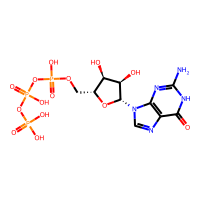
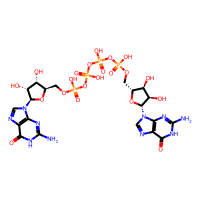
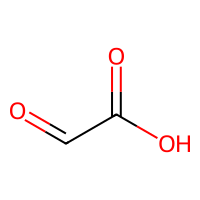
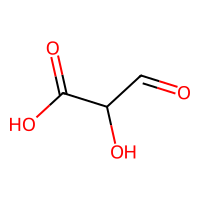
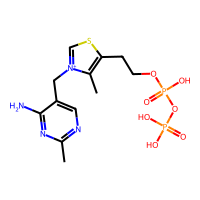
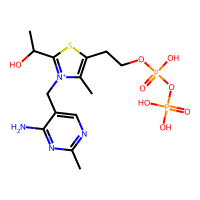
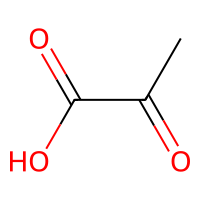
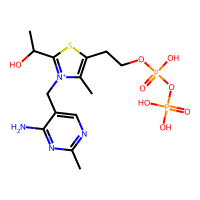
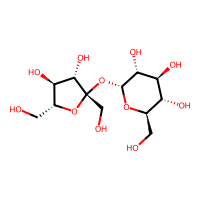
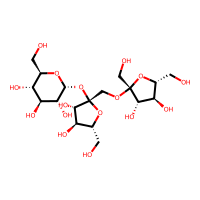
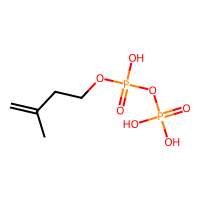
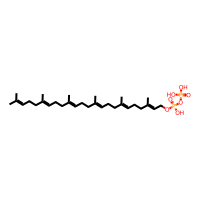
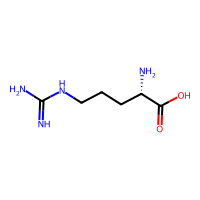
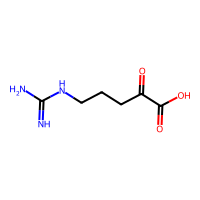
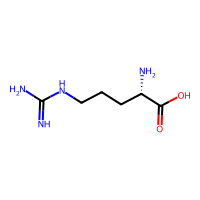
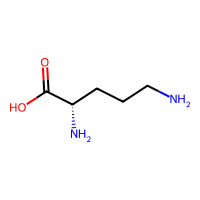
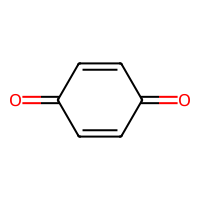
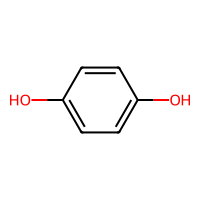
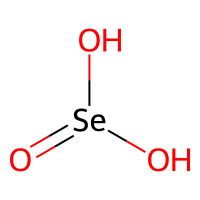
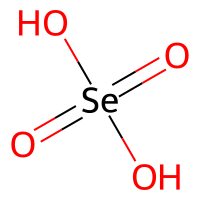

In [6]:
df_cpd = pd.read_parquet('../reactions/KEGG_cpd.gzip', engine='fastparquet')
df_cpd = df_cpd.iloc[20:].dropna(subset=['FORMULA', 'INCHI', 'REACTION'])
entry_to_smiles = (df_cpd[['ENTRY', 'ISOSMILES']].set_index('ENTRY')['ISOSMILES'].to_dict())

def _parse_equation_side(side):
    coeffs = {}
    for term in side.split('+'):
        term = term.strip()
        if not term:
            continue

        coeff_match = re.match(r'^(\d+(?:\.\d+)?)\s+', term)
        coeff = float(coeff_match.group(1)) if coeff_match else 1.0
        id_match = re.search(r'([A-Z]\d{5})\s*$', term)
        if id_match:
            entry = id_match.group(1)
            coeffs[entry] = coeffs.get(entry, 0.0) + coeff
    return coeffs

def _format_coeff(x):
    return str(int(x)) if float(x).is_integer() else str(x)

def _extract_ratio(equation, reactant_id, product_id):
    if pd.isna(equation) or pd.isna(reactant_id) or pd.isna(product_id):
        return None

    sides = re.split(r'\s*(?:<=>|<->|=>|->|=)\s*', str(equation), maxsplit=1)
    if len(sides) != 2:
        return None

    left = _parse_equation_side(sides[0])
    right = _parse_equation_side(sides[1])
    r_coeff = left.get(reactant_id)
    p_coeff = right.get(product_id)
    if r_coeff is None or p_coeff is None:
        return None
    return f"{_format_coeff(r_coeff)}:{_format_coeff(p_coeff)}"

df1 = pd.read_parquet('../reactions/KEGG_rn.gzip', engine='fastparquet').explode('RPAIR')
pair_parts = df1['RPAIR'].str.split('_', n=1, expand=True)
df1['Reactant_ID'] = pair_parts[0]
df1['Product_ID'] = pair_parts[1]
df1['Ratio'] = df1.apply(lambda row: _extract_ratio(row['EQUATION'], row['Reactant_ID'], row['Product_ID']), axis=1)
df1['Reactant_SMILES'] = df1['Reactant_ID'].map(entry_to_smiles)
df1['Product_SMILES'] = df1['Product_ID'].map(entry_to_smiles)
df1 = df1.dropna(subset=['Reactant_SMILES', 'Product_SMILES', 'Ratio'])
df1 = df1[['Reactant_ID', 'Product_ID', 'Reactant_SMILES', 'Product_SMILES', 'Ratio']]
PandasTools.AddMoleculeColumnToFrame(df1, 'Reactant_SMILES', 'ROMol_R')
PandasTools.AddMoleculeColumnToFrame(df1, 'Product_SMILES', 'ROMol_P')
df1

In [ ]:
# fingerprint + similarity
methods = ['maccs']  # extend as needed

all_mols = pd.concat([df_all['ROMol_R'], df_all['ROMol_P']], ignore_index=True)
uniq_mols = pd.Series(all_mols.unique())

for method in methods:
    fp_map = {id(m): fpt.calculate_fp(m, method=method) for m in uniq_mols}

    fp_r = [fp_map[id(m)] for m in df_all['ROMol_R'].values]
    fp_p = [fp_map[id(m)] for m in df_all['ROMol_P'].values]

    df_all[f'similarity_{method}'] = [fpt.get_similarity(a, b, method=method)
        for a, b in zip(fp_r, fp_p)]

In [ ]:
sys.path.append('/home/mattia/aiddtools')
import fingerprint_tools as fpt

methods = ['maccs', 'rdkit', 'atompair', 'map4', 'morgan2', 'morgan3', 'avalon', 'torsion']

all_mols = pd.concat([df_all['ROMol_R'], df_all['ROMol_P']], ignore_index=True)
uniq_mols = pd.Series(all_mols.unique())

for method in methods:
    fp_map = {id(m): fpt.calculate_fp(m, method=method) for m in uniq_mols}

    fp_r = [fp_map[id(m)] for m in df_all['ROMol_R'].values]
    fp_p = [fp_map[id(m)] for m in df_all['ROMol_P'].values]

    df_all[f'similarity_{method}'] = [
        fpt.get_similarity(a, b, method=method)
        for a, b in zip(fp_r, fp_p)
    ]

# #.to_csv(R"C:\Users\Idener\Desktop\KEGG_RPAIRS.csv", index=False)
df_all

In [45]:
from collections import defaultdict

queries = defaultdict(list)

for i, row in df_all.iterrows():
    queries[id(row['ROMol_R'])].append(i)

def hits_at_k(df, score_col, k):
    hits = []
    for idxs in queries.values():
        sub = df.loc[idxs].sort_values(score_col, ascending=False)
        hits.append(sub.head(k)['label'].any())
    return sum(hits) / len(hits)


def mean_reciprocal_rank(df, score_col):
    rr = []
    for idxs in queries.values():
        sub = df.loc[idxs].sort_values(score_col, ascending=False)
        ranks = sub.index[sub['label'] == 1]
        if len(ranks) > 0:
            rank = sub.index.get_loc(ranks[0]) + 1
            rr.append(1 / rank)
        else:
            rr.append(0)
    return sum(rr) / len(rr)

methods = ['maccs', 'rdkit', 'atompair', 'map4',
           'morgan2', 'morgan3', 'avalon', 'torsion']

results = []

for m in methods:
    col = f'similarity_{m}'
    results.append({
        'fingerprint': m,
        'Hits@1': hits_at_k(df_all, col, 1),
        'Hits@5': hits_at_k(df_all, col, 5),
        'Hits@10': hits_at_k(df_all, col, 10),
        'MRR': mean_reciprocal_rank(df_all, col)
    })

df_per_query = pd.DataFrame(results).sort_values('MRR', ascending=False)
df_per_query

,fingerprint,Hits@1,Hits@5,Hits@10,MRR
2,atompair,0.916887,0.997357,1.000000,0.953017
3,map4,0.886050,0.993686,0.999853,0.932228
0,maccs,0.875037,0.994420,1.000000,0.928143
7,torsion,0.875330,0.994126,0.999853,0.926485
5,morgan3,0.873421,0.986197,0.999413,0.922100
4,morgan2,0.871659,0.986050,0.999559,0.921367
6,avalon,0.850073,0.989574,0.999853,0.911133
1,rdkit,0.840675,0.975037,0.998678,0.899452


How to interpret the results
Hits@1

how often the correct product is ranked first

very strict

Hits@5 / Hits@10

how often the correct answer appears among the top suggestions

this is usually the most relevant metric

MRR

combines early ranking quality into a single number

higher is always better

sensitive to fine ranking differences

In [ ]:
# Try PubCehm FP: https://www.pingzhang.net/bak/drugreposition/list_fingerprints.pdf
# Also other FPs: https://scispace.com/pdf/development-of-natural-compound-molecular-fingerprint-nc-mfp-1uhuehgn6u.pdf